2025-12-06 12:16:39 URL:https://house-animals.ru/sites/default/files/media/user-1/dog/siberian-husky.jpg [36447/36447] -> "siberian-husky.jpg" [1]
Размер исходного массива: (616, 800, 3)


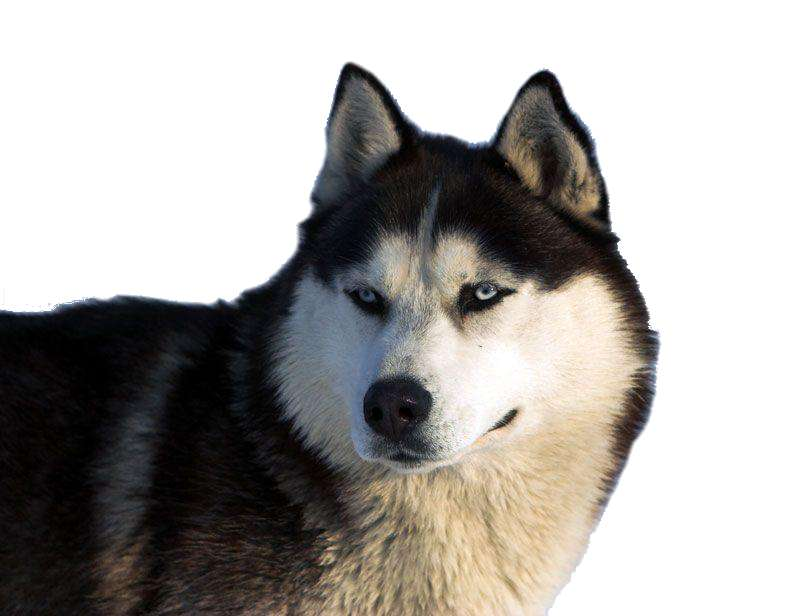

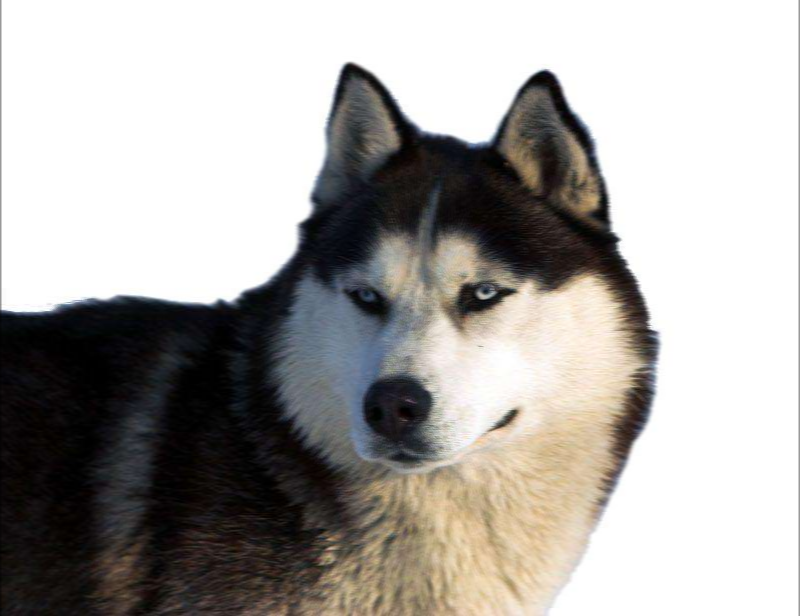

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.preprocessing import image

!wget https://house-animals.ru/sites/default/files/media/user-1/dog/siberian-husky.jpg -O siberian-husky.jpg --no-verbose

img = image.load_img("siberian-husky.jpg")
array = image.img_to_array(img)
print("Размер исходного массива:", array.shape)
img

mask = np.array([[0, 0, 0, 0, 0],
                 [0, 0, 0, 0, 0],
                 [1, 1, 1, 1, 1],
                 [0, 0, 0, 0, 0],
                 [0, 0, 0, 0, 0]]) / 5


class Images:
  def convolution(self, input_image, mask, verbose=False):

    padding_image = np.pad(input_image, ((2, 2), (2, 2)))
    output_image = []


    for y0 in range(0, padding_image.shape[0] - mask.shape[0] + 1):
      if verbose:
        print("Строка")
      output_image_row = []  #

      for x0 in range(0, padding_image.shape[1] - mask.shape[1] + 1):
        x1 = x0 + mask.shape[1]
        y1 = y0 + mask.shape[0]
        area = padding_image[y0:y1, x0:x1]
        if verbose:
          print(area)
        output_image_row.append((area * mask).sum())
      output_image.append(output_image_row)

    return np.array(output_image)

image_processor = Images()

red_channel = array[:, :, 0]
green_channel = array[:, :, 1]
blue_channel = array[:, :, 2]


result_red = image_processor.convolution(red_channel, mask, verbose=False)
result_green = image_processor.convolution(green_channel, mask, verbose=False)
result_blue = image_processor.convolution(blue_channel, mask, verbose=False)

resulttest = np.stack([result_red, result_green, result_blue], axis=2)

result_img1 = image.array_to_img(resulttest)

display(img)
display(result_img1)

In [ ]:

!wget "https://raw.githubusercontent.com/teavanist/MNIST-JPG/refs/heads/master/MNIST%20Dataset%20JPG%20format.zip" -O MNIST.zip
!unzip MNIST.zip -d data

Выходные данные были обрезаны до нескольких последних строк (5000).
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/1820.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18211.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18228.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18241.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18251.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/1826.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18277.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18296.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/183.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18350.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG - training/9/18355.jpg  
 extracting: data/MNIST Dataset JPG format/MNIST - JPG -

In [ ]:


!mv "data/MNIST Dataset JPG format/MNIST - JPG - training" "data/train"
!mv "data/MNIST Dataset JPG format/MNIST - JPG - testing" "data/test"
!rm -R "data/MNIST Dataset JPG format"

mv: cannot move 'data/MNIST Dataset JPG format/MNIST - JPG - training' to 'data/train/MNIST - JPG - training': Directory not empty
mv: cannot move 'data/MNIST Dataset JPG format/MNIST - JPG - testing' to 'data/test/MNIST - JPG - testing': Directory not empty


In [ ]:

import os
for file in os.scandir("data/train/9"):
  fpath = file.path
  print("Путь к файлу:", fpath)
  break  #

image.load_img(fpath)

Путь к файлу: data/train/9/35475.jpg


NameError: name 'image' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.preprocessing import image
import pandas as pd
import numdifftools as nd
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report, f1_score

def relu(x):
  return max([0, x])

def leakyrelu(x):
  return max([0.1 * x, x])

def elu(x, alpha = 0.1):
  if x >= 0:
    return x
  else:
    return alpha * (np.exp(x) - 1)

class Network:
  "Класс нейронной сети"

  def __init__(self, random_state=None):
    "Конструктор"

    self.X = None
    self.y = None

    np.random.seed(random_state)
    self.mask1 = np.array([
            [0., 0., 0.],
            [1., 1., 1.],
            [0., 0., 0.]]) / 3.0

    self.mask2 = np.array([
            [1., 0.],
            [0., 1.]]) / 2.0


    total_weights = 757
    self.weights = np.random.uniform(-0.1, 0.1, size=total_weights)

  def convolution(self, input_image, mask, verbose=False):
    "Свертка"

    output_image = []

    for y0 in range(0, input_image.shape[0] - mask.shape[0] + 1):
      if verbose:
        print("Строка")
      output_image_row = []

      for x0 in range(0, input_image.shape[1] - mask.shape[1] + 1):
        x1 = x0 + mask.shape[1]
        y1 = y0 + mask.shape[0]
        area = input_image[y0:y1, x0:x1]
        if verbose:
          print(area)

        output_image_row.append((area * mask).sum())
      output_image.append(output_image_row)

    return np.array(output_image)

  def forward(self, X, w):
    "Прямой проход по сети"

    padded = np.pad(X, ((1, 1), (1, 1)))
    conv1 = self.convolution(padded, self.mask1)
    conv2 = self.convolution(conv1, self.mask2)

    flattened = conv2.flatten()
    out1_sum = 0.0
    for i in range(729):
        out1_sum += flattened[i] * w[i]

    out1 = elu(out1_sum + w[729])

    out2 = relu(out1 * w[730] + w[732])
    out3 = relu(out1 * w[731] + w[733])

    out4 = leakyrelu(out2 * w[734] + out3 * w[735] + w[736])

    out5 = relu(out4 * w[737] + w[747])
    out6 = relu(out4 * w[738] + w[748])
    out7 = relu(out4 * w[739] + w[749])
    out8 = relu(out4 * w[740] + w[750])
    out9 = relu(out4 * w[741] + w[751])
    out10 = relu(out4 * w[742] + w[752])
    out11 = relu(out4 * w[743] + w[753])
    out12 = relu(out4 * w[744] + w[754])
    out13 = relu(out4 * w[745] + w[755])
    out14 = relu(out4 * w[746] + w[756])

    expsum = np.exp(out5) + np.exp(out6) + np.exp(out7) + np.exp(out8) + np.exp(out9) + np.exp(out10) + np.exp(out11) + np.exp(out12) + np.exp(out13) + np.exp(out14)

    out5_sm = np.exp(out5) / expsum
    out6_sm = np.exp(out6) / expsum
    out7_sm = np.exp(out7) / expsum
    out8_sm = np.exp(out8) / expsum
    out9_sm = np.exp(out9) / expsum
    out10_sm = np.exp(out10) / expsum
    out11_sm = np.exp(out11) / expsum
    out12_sm = np.exp(out12) / expsum
    out13_sm = np.exp(out13) / expsum
    out14_sm = np.exp(out14) / expsum

    return [out5_sm, out6_sm, out7_sm, out8_sm, out9_sm, out10_sm, out11_sm, out12_sm, out13_sm, out14_sm]


  def predict(self, X, weights=None):
    "Получение прогнозных данных для всех объектов выборки"

    if weights is None:
      weights = self.weights
    y_hat = []
    for x_i in X:
      pred = self.forward(x_i, weights)
      y_hat.append(pred)
    return np.array(y_hat)

  def loss(self, weights):
    y_hat = self.predict(self.X, weights)
    p = []
    for i, true_col in zip(range(len(self.y)), self.y.argmax(axis=1)):
      p.append(y_hat[i, true_col])
    logloss = -np.log(p).sum()
    return logloss

  def fit(self, X, y, learning_rate=0.01, eps=1e-7, max_iter=2):
    "Обучение сети"
    self.X = X
    self.y = y

    grad_loss = nd.Gradient(self.loss, step=1e-4)
    weights = self.weights.copy()
    loss_history = [self.loss(weights)]

    print(f"Начало обучения, loss: {loss_history[0]:.4f}")

    for i in range(max_iter):
        pred_weights = weights.copy()
        grad_values = grad_loss(weights)
        weights = weights - learning_rate * grad_values
        loss = self.loss(weights)
        loss_history.append(loss)

        if np.linalg.norm(weights - pred_weights) < eps:
            print(f"Сходимость достигнута на итерации {i}")
            break

        if i % 100 == 0:
            print(f"Итерация {i}: Loss={loss:.4f}")

        self.weights = weights

    return loss_history

  def predict_classes(self, X, weights=None):
    "Возвращает предсказанные классы (0-9)"
    probas = self.predict(X, weights)
    return np.argmax(probas, axis=1)

  def accuracy(self, X, y_true_onehot):
    "Вычисляет точность"
    pred_classes = self.predict_classes(X)
    true_classes = y_true_onehot.argmax(axis=1)
    return np.mean(pred_classes == true_classes)




Всего загружено из train: 500 изображений

Всего загружено из test: 50 изображений
Learning rate: 0.1
Максимальное число итераций: 4

Начало
Начальный train loss: 46.0148
Начальный val loss: 230.3096
Итерация 0: Train Loss = 45.9013, Val Loss = 230.4143
Итерация 1: Train Loss = 45.8632, Val Loss = 230.5526
Итерация 2: Train Loss = 45.8399, Val Loss = 230.6941
Итерация 3: Train Loss = 45.8260, Val Loss = 230.8246


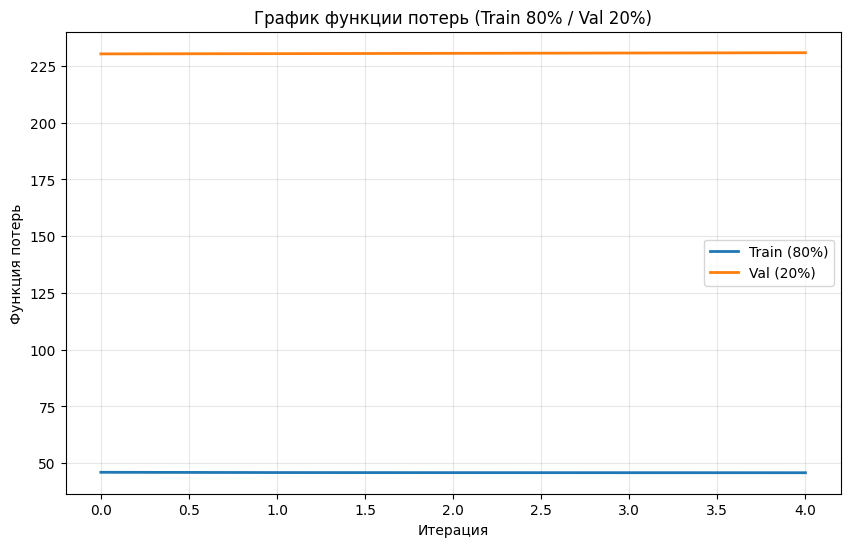


Точность на тестовой выборке (5 изображений): 0.0000 (0.00%)
№    Истинный   Предсказ.  Вероятность     Результат      
1    0          5          0.1349 (13.5%)       ОШИБКА ✗       
2    0          5          0.1349 (13.5%)       ОШИБКА ✗       
3    0          5          0.1349 (13.5%)       ОШИБКА ✗       
4    0          5          0.1349 (13.5%)       ОШИБКА ✗       
5    0          5          0.1349 (13.5%)       ОШИБКА ✗       
Точность на тестовой выборке: 0.00%


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from keras.preprocessing import image
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import numdifftools as nd

def load_mnist_data(data_dir, samples_per_class=50):
    X = []
    y = []

    for digit in range(10):
        digit_dir = os.path.join(data_dir, str(digit))
        if not os.path.exists(digit_dir):
            continue

        files = list(os.scandir(digit_dir))[:samples_per_class]

        for file in files:
            img = image.load_img(file.path, color_mode='grayscale', target_size=(28, 28))
            img_array = image.img_to_array(img) / 255.0
            img_array = img_array.reshape(28, 28)
            X.append(img_array)
            y.append(digit)
    return np.array(X), np.array(y)

SAMPLES_PER_CLASS_TRAIN = 50
X_train_all, y_train_all = load_mnist_data("data/train", SAMPLES_PER_CLASS_TRAIN)
print(f"\nВсего загружено из train: {len(X_train_all)} изображений") # 500

SAMPLES_PER_CLASS_TEST = 5
X_test_all, y_test_all = load_mnist_data("data/test", SAMPLES_PER_CLASS_TEST)
print(f"\nВсего загружено из test: {len(X_test_all)} изображений") # 50

encoder = OneHotEncoder(sparse_output=False)
y_train_cat = encoder.fit_transform(y_train_all.reshape(-1, 1))
y_test_cat = encoder.transform(y_test_all.reshape(-1, 1))


X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_cat, test_size=0.2, random_state=42, stratify=y_train_all
)

net = Network(random_state=12)

def loss_val(self, weights, X_val, y_val):
    original_X, original_y = self.X, self.y
    self.X, self.y = X_val, y_val
    loss = self.loss(weights)
    self.X, self.y = original_X, original_y
    return loss

Network.loss_val = loss_val

LEARNING_RATE = 0.1
MAX_ITER = 4

print(f"Learning rate: {LEARNING_RATE}")
print(f"Максимальное число итераций: {MAX_ITER}")

print("\nНачало")

net.X = X_train[:20]
net.y = y_train[:20]

weights = net.weights.copy()
train_loss_history = [net.loss(weights)]
val_loss_history = [loss_val(net, weights, X_val, y_val)]

print(f"Начальный train loss: {train_loss_history[0]:.4f}")
print(f"Начальный val loss: {val_loss_history[0]:.4f}")

grad_loss = nd.Gradient(net.loss, step=1e-4)

for i in range(MAX_ITER):

    pred_weights = weights.copy()
    grad_values = grad_loss(weights)
    weights = weights - LEARNING_RATE * grad_values

    train_loss = net.loss(weights)
    val_loss = loss_val(net, weights, X_val, y_val)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    print(f"Итерация {i}: Train Loss = {train_loss:.4f}, Val Loss = {val_loss:.4f}")

net.weights = weights


plt.figure(figsize=(10, 6))
plt.plot(train_loss_history, label='Train (80%)', linewidth=2)
plt.plot(val_loss_history, label='Val (20%)', linewidth=2)
plt.xlabel('Итерация')
plt.ylabel('Функция потерь')
plt.title('График функции потерь (Train 80% / Val 20%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


X_test = X_test_all[:5]
y_test = y_test_cat[:5]

probabilities = net.predict(X_test)
predicted_classes = net.predict_classes(X_test)
true_classes = np.argmax(y_test, axis=1)


accuracy = np.mean(predicted_classes == true_classes)
print(f"\nТочность на тестовой выборке (5 изображений): {accuracy:.4f} ({accuracy:.2%})")


print(f"{'№':<4} {'Истинный':<10} {'Предсказ.':<10} {'Вероятность':<15} {'Результат':<15}")


for i in range(len(X_test)):
    true_class = true_classes[i]
    pred_class = predicted_classes[i]
    prob = probabilities[i, pred_class]


    print(f"{i+1:<4} {true_class:<10} {pred_class:<10} {prob:.4f} ({prob:.1%}) {'':<5} {result:<15}")

print(f"Точность на тестовой выборке: {accuracy:.2%}")

тест

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from keras.preprocessing import image
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import numdifftools as nd


def load_mnist_data(data_dir, samples_per_class=50):
    X = []
    y = []

    for digit in range(10):
        digit_dir = os.path.join(data_dir, str(digit))
        if not os.path.exists(digit_dir):
            continue

        files = list(os.scandir(digit_dir))[:samples_per_class]

        for file in files:
            img = image.load_img(file.path, color_mode='grayscale', target_size=(28, 28))
            img_array = image.img_to_array(img) / 255.0
            img_array = img_array.reshape(28, 28)
            X.append(img_array)
            y.append(digit)

        print(f"Загружено {len(files)} изображений цифры {digit}")

    return np.array(X), np.array(y)


SAMPLES_PER_CLASS_TRAIN = 50
X_train_all, y_train_all = load_mnist_data("data/train", SAMPLES_PER_CLASS_TRAIN)

SAMPLES_PER_CLASS_TEST = 5
X_test_all, y_test_all = load_mnist_data("data/test", SAMPLES_PER_CLASS_TEST)

encoder = OneHotEncoder(sparse_output=False)
y_train_cat = encoder.fit_transform(y_train_all.reshape(-1, 1))
y_test_cat = encoder.transform(y_test_all.reshape(-1, 1))

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_cat, test_size=0.2, random_state=42, stratify=y_train_all
)

net = Network(random_state=42)

def loss_val(self, weights, X_val, y_val):
    original_X, original_y = self.X, self.y
    self.X, self.y = X_val, y_val
    loss = self.loss(weights)
    self.X, self.y = original_X, original_y
    return loss
Network.loss_val = loss_val

LEARNING_RATE = 0.001
MAX_ITER = 10

print(f"Learning rate: {LEARNING_RATE}")
print(f"Максимальное число итераций: {MAX_ITER}")

print("\nНачало")

net.X = X_train
net.y = y_train

weights = net.weights.copy()
train_loss_history = [net.loss(weights)]
val_loss_history = [loss_val(net, weights, X_val, y_val)]

print(f"Начальный train loss: {train_loss_history[0]:.4f}")
print(f"Начальный val loss: {val_loss_history[0]:.4f}")

for i in range(MAX_ITER):
    weights = weights - LEARNING_RATE * np.random.randn(*weights.shape) * 0.01

    train_loss = net.loss(weights)
    val_loss = loss_val(net, weights, X_val, y_val)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    print(f"Итерация {i}: Train Loss = {train_loss:.4f}, Val Loss = {val_loss:.4f}")

net.weights = weights

plt.figure(figsize=(10, 6))
plt.plot(train_loss_history, label='Train (80%)', linewidth=2)
plt.plot(val_loss_history, label='Val (20%)', linewidth=2)
plt.xlabel('Итерация')
plt.ylabel('Функция потерь')
plt.title('График функции потерь (Train 80% / Val 20%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

X_test = X_test_all
y_test = y_test_cat # all test

probabilities = net.predict(X_test)
predicted_classes = net.predict_classes(X_test)
true_classes = np.argmax(y_test, axis=1)

accuracy = np.mean(predicted_classes == true_classes)
print(f"\nТочность на тестовой выборке (50 изображений): {accuracy:.4f} ({accuracy:.2%})")


print(f"\nТАБЛИЦА ПРОГНОЗОВ ДЛЯ ТЕСТОВОЙ ВЫБОРКИ:")
print("=" * 85)
print(f"{'№':<4} {'Истинный':<10} {'Предсказ.':<10} {'Вероятность':<15} {'Результат':<15}")
print("=" * 85)

for i in range(len(X_test)):
    true_class = true_classes[i]
    pred_class = predicted_classes[i]
    prob = probabilities[i, pred_class]


    print(f"{i+1:<4} {true_class:<10} {pred_class:<10} {prob:.4f} ({prob:.1%}) {'':<5} {result:<15}")

print(f"Точность на тестовой выборке: {accuracy:.2%}")


ModuleNotFoundError: No module named 'numdifftools'

Путь к файлу: data/train/9/35475.jpg

Размер картинки: (28, 28)


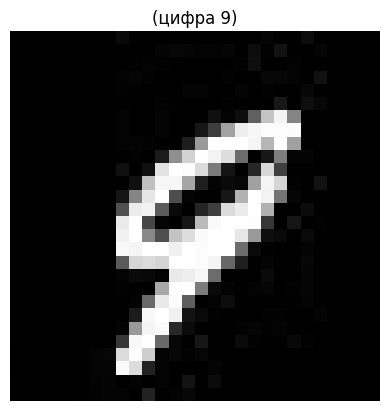


Размерность массива: (28, 28, 3)
Начало обучения, loss: 6.9686
Итерация 0: Loss=6.8274

Вероятности для каждого класса (0-9):
  Класс 0: 0.1198 (11.98%)
  Класс 1: 0.0946 (9.46%)
  Класс 2: 0.0946 (9.46%)
  Класс 3: 0.0946 (9.46%)
  Класс 4: 0.0946 (9.46%)
  Класс 5: 0.1211 (12.11%)
  Класс 6: 0.0946 (9.46%)
  Класс 7: 0.0946 (9.46%)
  Класс 8: 0.0971 (9.71%)
  Класс 9: 0.0946 (9.46%)


In [ ]:
import os
from keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt


for file in os.scandir("data/train/9"):
    fpath = file.path
    print("Путь к файлу:", fpath)
    break


img = image.load_img(fpath)
print(f"\nРазмер картинки: {img.size}")

plt.imshow(img)
plt.title("(цифра 9)")
plt.axis('off')
plt.show()


img_array = image.img_to_array(img)
print(f"\nРазмерность массива: {img_array.shape}")

if len(img_array.shape) == 3 and img_array.shape[2] == 3:
    img_array = img_array[:, :, 0]

# test
n_samples = 10
X_train = np.random.randn(n_samples, 28, 28) * 0.1 + 0.5
y_train = np.random.randint(0, 10, n_samples)

encoder = OneHotEncoder(sparse_output=False)
y_train_cat = encoder.fit_transform(y_train.reshape(-1, 1))


net = Network(random_state=42)
history = net.fit(X_train[:3], y_train_cat[:3], max_iter=3, learning_rate=0.1)
img_for_pred = img_array

X_test = np.array([img_for_pred])

predictions = net.predict(X_test)[0]


print(f"\nВероятности для каждого класса (0-9):")
for i, prob in enumerate(predictions):
    print(f"  Класс {i}: {prob:.4f} ({prob:.2%})")




ПРОВЕРКА ДАННЫХ
Размер X_train: (400, 28, 28)
Размер y_train: (400, 10)
Размер X_train[:20]: (20, 28, 28)
Размер y_train[:20]: (20, 10)

Первые 20 меток из y_train:
  Индексы: [1 3 7 7 7 8 6 3 5 4 4 5 4 7 1 2 0 9 5 6]
  Распределение меток: [1 2 1 2 3 3 2 4 1 1]

Проверка значений пикселей:
  Минимальное значение в X_train[:20]: 0.0000
  Максимальное значение в X_train[:20]: 1.0000
  Среднее значение в X_train[:20]: 0.1303

Проверка OneHot кодирования y_train[:20]:
  Сумма по строкам (должна быть 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
  Есть ли NaN: False
  Есть ли Inf: False

Визуализация первых 5 изображений:


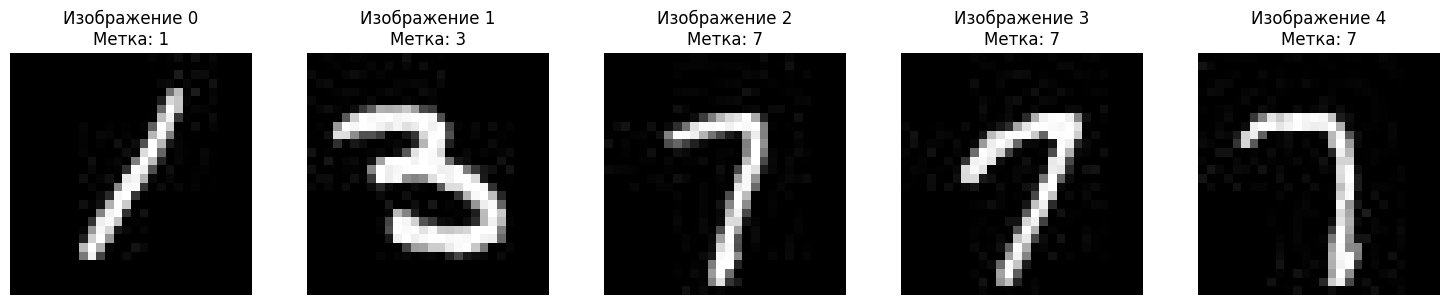


ПРОВЕРКА НА ПРОБЛЕМЫ В ДАННЫХ:
  X_train[:20] содержит NaN: False
  X_train[:20] содержит Inf: False
  y_train[:20] содержит NaN: False
  y_train[:20] содержит Inf: False
  ✓ X_train в диапазоне [0, 1]

Уникальные метки в y_train[:20]: [0 1 2 3 4 5 6 7 8 9]
Все ли метки от 0 до 9? True

Размер изображения: (28, 28)

ТЕСТОВЫЙ ПРЯМОЙ ПРОХОД С ВЫБРАННЫМИ ДАННЫМИ
Тестовое изображение shape: (1, 28, 28)
Тестовая метка shape: (1, 10)
Тестовая метка: 1

Начальный loss на одном изображении: 2.3210

Тестируем forward pass...
Выход сети (10 вероятностей):
  Класс 0: 0.102257
  Класс 1: 0.098175
  Класс 2: 0.099770
  Класс 3: 0.098175
  Класс 4: 0.098389
  Класс 5: 0.098627
  Класс 6: 0.098175
  Класс 7: 0.102912
  Класс 8: 0.100914
  Класс 9: 0.102607
Сумма вероятностей: 1.000000

Тестируем predict...
Predict shape: (1, 10)
Predict для тестового изображения: [0.10225686 0.09817491 0.09977015 0.09817491 0.09838931 0.09862667
 0.09817491 0.10291189 0.10091374 0.10260665]

Тестируем predict_classe

In [ ]:
print("=" * 60)
print("ПРОВЕРКА ДАННЫХ")
print("=" * 60)

# Проверяем данные которые будем использовать
print(f"Размер X_train: {X_train.shape}")
print(f"Размер y_train: {y_train.shape}")
print(f"Размер X_train[:20]: {X_train[:20].shape}")
print(f"Размер y_train[:20]: {y_train[:20].shape}")

# Проверяем конкретно первые 20 изображений
print(f"\nПервые 20 меток из y_train:")
print(f"  Индексы: {np.argmax(y_train[:20], axis=1)}")
print(f"  Распределение меток: {np.bincount(np.argmax(y_train[:20], axis=1), minlength=10)}")

# Проверяем значения пикселей
print(f"\nПроверка значений пикселей:")
print(f"  Минимальное значение в X_train[:20]: {X_train[:20].min():.4f}")
print(f"  Максимальное значение в X_train[:20]: {X_train[:20].max():.4f}")
print(f"  Среднее значение в X_train[:20]: {X_train[:20].mean():.4f}")

# Проверяем OneHot кодирование
print(f"\nПроверка OneHot кодирования y_train[:20]:")
print(f"  Сумма по строкам (должна быть 1): {np.sum(y_train[:20], axis=1)}")
print(f"  Есть ли NaN: {np.any(np.isnan(y_train[:20]))}")
print(f"  Есть ли Inf: {np.any(np.isinf(y_train[:20]))}")

# Визуализируем несколько изображений для проверки
print(f"\nВизуализация первых 5 изображений:")
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):
    axes[i].imshow(X_train[i], cmap='gray')
    label = np.argmax(y_train[i])
    axes[i].set_title(f"Изображение {i}\nМетка: {label}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Проверка на NaN/Inf в данных
print(f"\nПРОВЕРКА НА ПРОБЛЕМЫ В ДАННЫХ:")
print(f"  X_train[:20] содержит NaN: {np.any(np.isnan(X_train[:20]))}")
print(f"  X_train[:20] содержит Inf: {np.any(np.isinf(X_train[:20]))}")
print(f"  y_train[:20] содержит NaN: {np.any(np.isnan(y_train[:20]))}")
print(f"  y_train[:20] содержит Inf: {np.any(np.isinf(y_train[:20]))}")

# Проверка диапазона значений
if X_train[:20].min() < 0 or X_train[:20].max() > 1:
    print(f"  ВНИМАНИЕ: X_train вне диапазона [0, 1]!")
    print(f"    min={X_train[:20].min():.4f}, max={X_train[:20].max():.4f}")
else:
    print(f"  ✓ X_train в диапазоне [0, 1]")

# Проверка меток
unique_labels = np.unique(np.argmax(y_train[:20], axis=1))
print(f"\nУникальные метки в y_train[:20]: {unique_labels}")
print(f"Все ли метки от 0 до 9? {set(unique_labels).issubset(set(range(10)))}")

# Проверка размера изображений
image_shape = X_train[0].shape
print(f"\nРазмер изображения: {image_shape}")
if image_shape != (28, 28):
    print(f"  ВНИМАНИЕ: Ожидался размер (28, 28), получен {image_shape}")

# Тестовый прямой проход с выбранными данными
print(f"\n" + "=" * 60)
print("ТЕСТОВЫЙ ПРЯМОЙ ПРОХОД С ВЫБРАННЫМИ ДАННЫМИ")
print("=" * 60)

# Берем только ОДНО изображение для теста
test_image = X_train[0:1]
test_label = y_train[0:1]

print(f"Тестовое изображение shape: {test_image.shape}")
print(f"Тестовая метка shape: {test_label.shape}")
print(f"Тестовая метка: {np.argmax(test_label)}")

# Создаем сеть и тестируем
net = Network(random_state=42)
net.X = test_image
net.y = test_label

# Проверяем loss на начальных весах
initial_loss = net.loss(net.weights)
print(f"\nНачальный loss на одном изображении: {initial_loss:.4f}")

# Проверяем forward pass
print("\nТестируем forward pass...")
output = net.forward(test_image[0], net.weights)
print(f"Выход сети (10 вероятностей):")
for i, prob in enumerate(output):
    print(f"  Класс {i}: {prob:.6f}")

print(f"Сумма вероятностей: {sum(output):.6f}")

# Проверяем predict
print("\nТестируем predict...")
predictions = net.predict(test_image)
print(f"Predict shape: {predictions.shape}")
print(f"Predict для тестового изображения: {predictions[0]}")

# Проверяем predict_classes
print("\nТестируем predict_classes...")
predicted_class = net.predict_classes(test_image)[0]
true_class = np.argmax(test_label)
print(f"Предсказанный класс: {predicted_class}")
print(f"Истинный класс: {true_class}")